# Basic Model for Count Data
We will start by looking at models for *count* data. This type of data has several key properties that make the standard linear model inappropriate. The main concern is that counts cannot go below 0. As such, the model must be bounded to only produce predictions from 0 to (in principle) $\infty$. Counts can also only be whole numbers. However, many discrete distributions allow their parameters to take on fractional values, meaning that we can model the *average count* without must additional concern. This actually makes count data more amenable to linear modelling than binary data. The key difference is that, particularly for low numbers of counts, the marginal distribution will be highly skewed. Furthermore, in many real-world applications there may be an excess of 0's, depending upon the rarity of the event being counted. As such, choice of distribution is key.



## Distribution
The most common distribution used for count data is the Poisson. Other distributions, such as the *negative binomial*, are also used, but the Poisson remains the *default* choice for count data and is therefore the distribution we will focus on. As such, our main assumption is that the data can be modelled as

$$
y_{i} \sim \text{Pois}\left(\lambda_{i}\right),
$$

with a mean and variance given by

$$
\begin{align*}
    E(y_{i})          &= \mu_{i} = \lambda_{i} \\
    \text{Var}(y_{i}) &= \mu_{i} = \lambda_{i}. 
\end{align*}
$$

As should be clear, the Poisson only has a single parameter ($\lambda$) that gives the *average count*. Furthermore, this value also describes the *variance* of the Poisson distribution. Because of this, larger average counts will mean a wider distribution and lower average counts will mean a narrow distribution. These two aspects are inextricably linked and cannot be separated. This makes the Poisson very simple, but also rather *inflexible*.

You can visualise the Poisson distribution and how it changes for different values of $\lambda$ in the [Probability Playground](https://probabilityplayground.com/poisson).

### Types of Count Data
It is also important at this stage to distinguish between the type of counts that can be modelled with binomial logistic regression and the type of counts we are focussing on this week. Under a binomial model, the counts are based on the number of success in a *fixed number of trials*. As such, the count is based on binary events and a fixed total. For instance, scores on a memory test where each item is either *recognised* or *not recognised*. As there are a fixed number of trials and each trial is binary, the binomial distribution would be more suitable than the Poisson. However, if we are counting numbers of events across a given interval of time, there is no real "total" number of trials. In these instances, the Poisson would be a better fit. For instance, the number of incoming telephone calls would be Poisson distributed. 

:::{admonition} Binomial Versus Poisson Counts
:class: tip
There is actually a deeper connection between the binomial and Poisson distributions, which may help with understanding their differences. There can, on the face of it, be ambiguities around whether something can be modelled as either binomial or Poisson. For instance, we could decide, when counting the number of customers who enter a shop over the course of an hour, to divide that time up into minutes and call it "60 trials". On each trial, a customer either enters or they do not. The binomial would then be perfectly suitable. However, what if two or more customers enter within the same minute? This counts only as a single "success", but is not distinguished correctly from only one customer entering. We could perhaps make the time intervals even smaller, perhaps down to the *second* or *millisecond*. As we do this, we are tending the number of trials $n \rightarrow \infty$, which will then make the probability of the event occurring on each trial smaller and smaller, tending $p \rightarrow 0$. And what happens with a binomial distribution as $n \rightarrow \infty$ and $p \rightarrow 0$? It converges on a Poisson distribution. So there is a deeper connection here. As the definition of "trial" becomes less well-defined due to stretching the counting over some interval, the binomial will simply turn into the Poisson. 
:::

### Overdispersion
As indicated above, a clear limitation of the Poisson model is that $E(y_{i}) = \text{Var}(y_{i}) = \lambda_{i}$. In practice, this can be difficult to justify as often the variance of counts can shift independently of the average count. In the context of Poisson regression, this is known as *overdispersion*. However, the GLM framework does provide a solution for this. Recall that the variance function for a GLM is given as

$$
\text{Var}\left(y_{i}\right) = \phi V(\mu_{i}).
$$

For standard Poisson model, we set

$$
\begin{align*}
    \phi       &= 1 \\
    V(\mu_{i}) &= \mu_{i} = \lambda_{i}.
\end{align*}
$$

However, we also have the option of *not* discarding $\phi$ and instead estimating its value. This will then scale the Poisson variance up or down by a constant amount. This is referred to as a *quasi-Poisson* model in `R` because, technically, the distribution is *not* Poisson if the variance does not equal the mean. This means that the model is not a true probability distribution, which has consequences that we will discuss later.

### Zero-inflation
Another aspect of real world count data is that there are often an *excessive* number of zeros. For instance, if the phenomena we are counting only occurs under a specific set of circumstances, then most of our attempts at observing it may result in a count of 0. This can lead to a dataset that has more zeros than the standard Poisson model can account for. An example is given in the plot below.

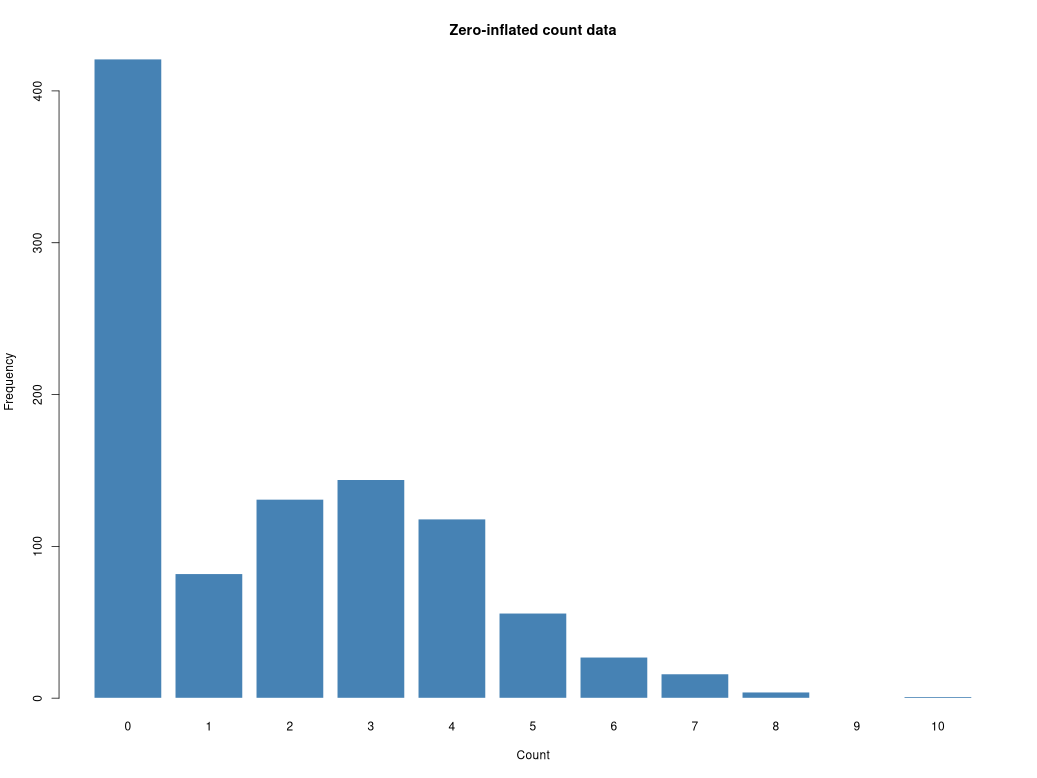

In [1]:
set.seed(123)

# Simulate Poisson counts
n <- 1000
y <- rpois(n, lambda = 3)

# Introduce 40% additional zeros
y[rbinom(n, size = 1, prob = 0.4) == 1] <- 0

# Plot the frequency distribution
barplot(table(factor(y, levels = 0:max(y))),
        xlab = "Count",
        ylab = "Frequency",
        main = "Zero-inflated count data",
        col = "steelblue",
        border = "white")

With these type of data, the idea is that there are actually *two* processes that are being captured, one that accounts for the zeros and one that accounts for the non-zero counts. As an example, consider the number of visits made to hospital in the space of 1 year counted across the population of the UK. The vast majority of people will make 0 visits in a year. However, for a subset of individuals, they may make many visits. The idea is that there are *two* different populations here. One is the average healthy individual, who will likely make 0 visits, and the other could be those with chronic health conditions who will likely make *multiple* visits. 

In these cases, we can use *zero-inflated* models. These approaches effectively fit two models, one that captures the excessive zeros and one that captures the counts after the zeros have been accommodated. In the example above, we can consider the chronic healthy condition group as Poisson distributed, with a separate probability process for the rest of the population. This is a type of *mixture model*, where the marginal distribution of the data concerns a mixture of multiple probability distributions. For zero-inflated models, there is one distribution that governs the probability of getting a 0 and one distribution that governs the probability of getting anything 0 and above.

## Link Function



### Lower Bound

### Multiplicative Effects
The other consequence of the log link is that, on the scale of the link function, we are not modelling a consistent change in the counts for each unit increase of the predictor. For example, under standard regression, we might predict that as the predictor increases the average count drops by 5. On the log scale, we are instead modelling change as a *proportion* of the previous value. So, rather than the average count dropping by 5 for each unit increase, it might instead drop by 20% of the previous value. 

This has a number of desirable properties. Firstly, the average count can never drop below 0 because it simply flattens more and more the closer you get to 0. 

Some example predictions are given in the table below. Notice that linear regression reduces the prediction by 4 each time. The log-link instead reduces the prediction by 20% of the previous value each time. Eventually, the linear regression model will cross 0 and start predicting impossible counts. The log-link will instead slowly curve gradually towards 0, but will never reach it. This is visualised in the plot below the table.


| Predictor (x) | Linear regression | Log-link regression |
|---:|---:|---:|
| 0 | 20 | 20.00 |
| 1 | 16 | 16.00 |
| 2 | 12 | 12.80 |
| 3 | 8 | 10.24 |
| 4 | 4 | 8.19 |
| 5 | 0 | 6.55 |
| 6 | -4 | 5.24 |
| 7 | -8 | 4.19 |
| 8 | -12 | 3.36 |


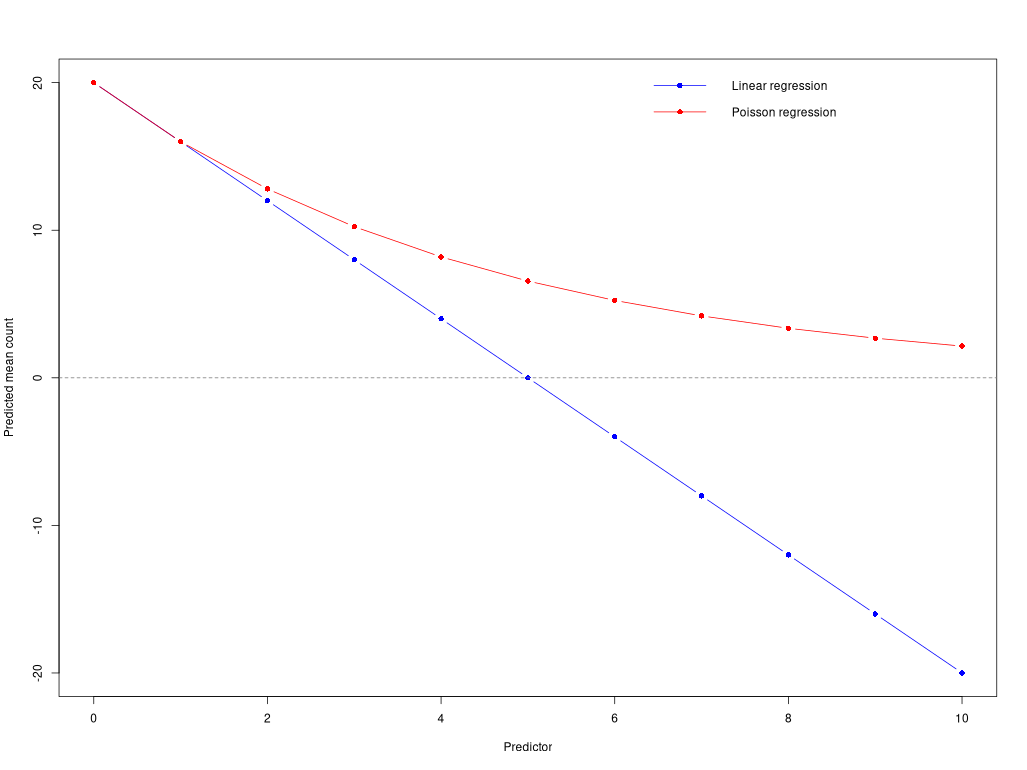

In [2]:
# Predictor values
x <- 0:10

# Predicted mean counts
linear <- 20 - 4*x
poisson <- 20 * 0.8^x

# Plot
plot(x, linear, type = "b", pch = 16, col = "blue",
     ylim = range(c(linear, poisson)),
     xlab = "Predictor",
     ylab = "Predicted mean count")

lines(x, poisson, type = "b", pch = 16, col = "red")

abline(h = 0, lty = 2, col = "grey50")

legend("topright",
       legend = c("Linear regression", "Poisson regression"),
       col = c("blue", "red"),
       lty = 1, pch = 16, bty = "n")


## Parameter Estimation


:::{tip .simple icon=false} What You Now Know
In this section, we have discussed the basic Poisson regression model for count data. After reading this section, you should have a good sense of:
- ...
- ...
:::